SETUP WORKSPACE:

In [1]:
# SET HYPERPARAMETERS

In [2]:
# IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_squared_error

DATA VALIDATION AND PREPARATION:

In [3]:
# LOAD DATA

df = pd.read_excel("grid_data.xlsx")

In [4]:
# INSPECT DATA

print(df.head())
print(df.describe())
print(df.isna().sum())

         Den      Perioda  Systémová odchylka\n(MWh)
0 2024-07-01  00:00-00:15                      7.846
1        NaT  00:15-00:30                      9.942
2        NaT  00:30-00:45                     -3.628
3        NaT  00:45-01:00                    -17.932
4        NaT  01:00-01:15                    -23.344
                       Den  Systémová odchylka\n(MWh)
count                   92                8832.000000
mean   2024-08-15 12:00:00                   0.817581
min    2024-07-01 00:00:00                -160.829000
25%    2024-07-23 18:00:00                 -11.047500
50%    2024-08-15 12:00:00                   0.754000
75%    2024-09-07 06:00:00                  13.508000
max    2024-09-30 00:00:00                 139.421000
std                    NaN                  21.628286
Den                          8740
Perioda                         0
Systémová odchylka\n(MWh)       0
dtype: int64


In [5]:
# ADJUST DATA

# SET DATETIME CORRECTLY
#Fill in the date to every row
for i in range(1, len(df)):
    if pd.isna(df.loc[i, 'Den']):  # Check if 'Den' is missing
        df.loc[i, 'Den'] = df.loc[i-1, 'Den']  # Assign the date from the previous row

# Make sure your 'Den' column is in datetime format (if needed)
df['Den'] = pd.to_datetime(df['Den'])
# Create an index variable starting from 1 to the number of rows in your DataFrame
df['Index'] = range(1, len(df) + 1)

In [6]:
# TRAIN TEST SPLIT

# Create a new column to indicate the split
validation_size = int(len(df) * 0.10)  # 10% of the data for validation
train_size = len(df) - validation_size  # Remaining 90% for training

# Split the data
train_data = df.iloc[:train_size].copy()  # Training data (first 90%)
validation_data = df.iloc[train_size:].copy()  # Validation data (last 10%)

# Add a new column to indicate the split
df['Split'] = 'Train'
df.loc[train_size:, 'Split'] = 'Validation'

# Check the split data
print(f"Training data size: {len(train_data)}")
print(f"Validation data size: {len(validation_data)}")

# Optional: Display first few rows of each dataset
print(train_data.head())
print(validation_data.head())

Training data size: 7949
Validation data size: 883
         Den      Perioda  Systémová odchylka\n(MWh)  Index
0 2024-07-01  00:00-00:15                      7.846      1
1 2024-07-01  00:15-00:30                      9.942      2
2 2024-07-01  00:30-00:45                     -3.628      3
3 2024-07-01  00:45-01:00                    -17.932      4
4 2024-07-01  01:00-01:15                    -23.344      5
            Den      Perioda  Systémová odchylka\n(MWh)  Index
7949 2024-09-21  19:15-19:30                     -9.986   7950
7950 2024-09-21  19:30-19:45                     -8.992   7951
7951 2024-09-21  19:45-20:00                     -9.302   7952
7952 2024-09-21  20:00-20:15                     -8.203   7953
7953 2024-09-21  20:15-20:30                    -10.840   7954


EXPLORATORY DATA ANALYSIS:

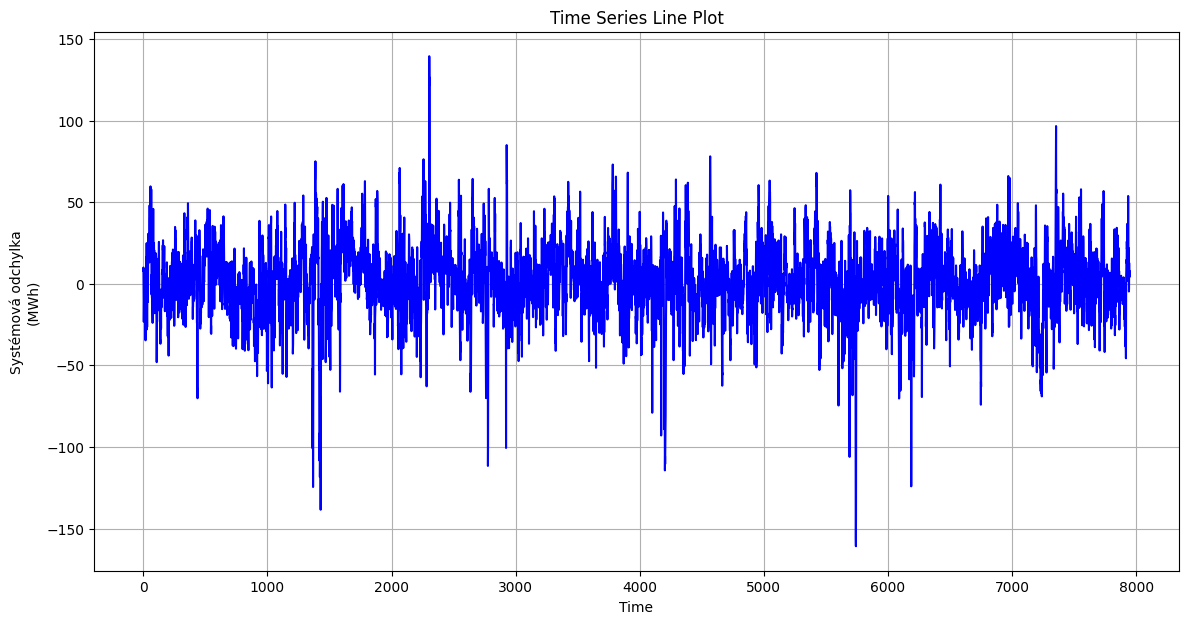

         Den      Perioda  Systémová odchylka\n(MWh)  Index
0 2024-07-01  00:00-00:15                      7.846      1
1 2024-07-01  00:15-00:30                      9.942      2
2 2024-07-01  00:30-00:45                     -3.628      3
3 2024-07-01  00:45-01:00                    -17.932      4
4 2024-07-01  01:00-01:15                    -23.344      5
Index(['Den', 'Perioda', 'Systémová odchylka\n(MWh)', 'Index'], dtype='str')


In [ ]:
# 1. Basic Line Plot of the time series
plt.figure(figsize=(14, 7))
plt.plot(train_data.index, train_data['Systémová odchylka\n(MWh)'], color='blue')
plt.title('Time Series Line Plot')
plt.xlabel('Time')
plt.ylabel('Systémová odchylka\n(MWh)')
plt.grid(True)
plt.show()

print(train_data.head())
print(train_data.columns)

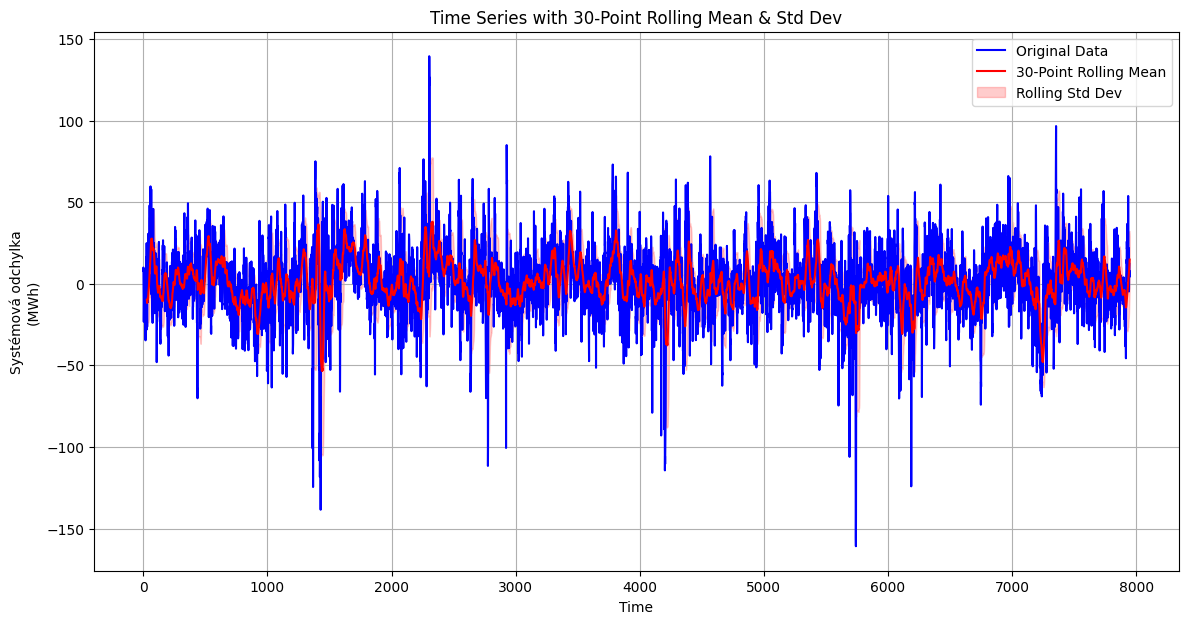

         Den      Perioda  Systémová odchylka\n(MWh)  Index  RollingMean  \
0 2024-07-01  00:00-00:15                      7.846      1          NaN   
1 2024-07-01  00:15-00:30                      9.942      2          NaN   
2 2024-07-01  00:30-00:45                     -3.628      3          NaN   
3 2024-07-01  00:45-01:00                    -17.932      4          NaN   
4 2024-07-01  01:00-01:15                    -23.344      5          NaN   

   RollingStd  
0         NaN  
1         NaN  
2         NaN  
3         NaN  
4         NaN  
Index(['Den', 'Perioda', 'Systémová odchylka\n(MWh)', 'Index', 'RollingMean',
       'RollingStd'],
      dtype='str')


In [8]:
# 2. Rolling Mean and Rolling Standard Deviation
window_size = 30  # Adjust the window to 30 periods (7.5 hours)
train_data['RollingMean'] = train_data['Systémová odchylka\n(MWh)'].rolling(window=window_size).mean()
train_data['RollingStd'] = train_data['Systémová odchylka\n(MWh)'].rolling(window=window_size).std()

plt.figure(figsize=(14, 7))
plt.plot(train_data.index, train_data['Systémová odchylka\n(MWh)'], color='blue', label='Original Data')
plt.plot(train_data.index, train_data['RollingMean'], color='red', label=f'{window_size}-Point Rolling Mean')
plt.fill_between(train_data.index, train_data['RollingMean'] - train_data['RollingStd'], train_data['RollingMean'] + train_data['RollingStd'],
                 color='red', alpha=0.2, label='Rolling Std Dev')
plt.title(f'Time Series with {window_size}-Point Rolling Mean & Std Dev')
plt.xlabel('Time')
plt.ylabel('Systémová odchylka\n(MWh)')
plt.legend()
plt.grid(True)
plt.show()

print(train_data.head())
print(train_data.columns)

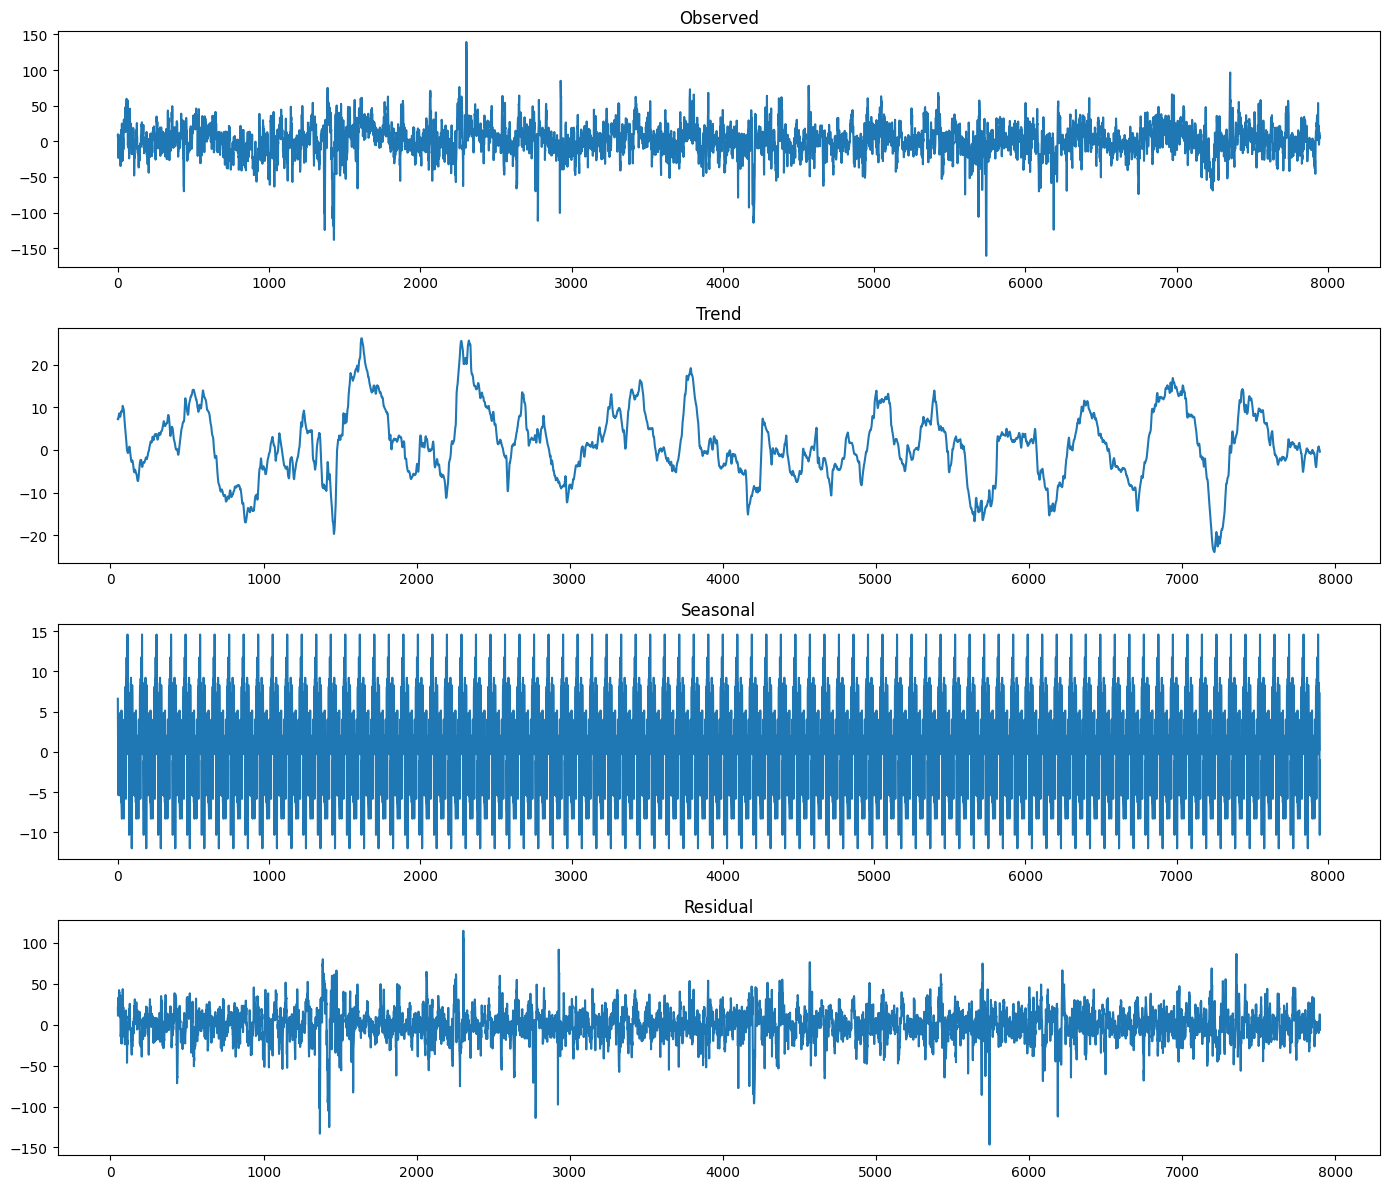

         Den      Perioda  Systémová odchylka\n(MWh)  Index  RollingMean  \
0 2024-07-01  00:00-00:15                      7.846      1          NaN   
1 2024-07-01  00:15-00:30                      9.942      2          NaN   
2 2024-07-01  00:30-00:45                     -3.628      3          NaN   
3 2024-07-01  00:45-01:00                    -17.932      4          NaN   
4 2024-07-01  01:00-01:15                    -23.344      5          NaN   

   RollingStd  
0         NaN  
1         NaN  
2         NaN  
3         NaN  
4         NaN  
Index(['Den', 'Perioda', 'Systémová odchylka\n(MWh)', 'Index', 'RollingMean',
       'RollingStd'],
      dtype='str')


In [ ]:
# 3. Seasonal Decomposition (Trend, Seasonal, and Residuals)
# Assuming daily seasonality (96 intervals per day for 15-minute data)
decomposition = seasonal_decompose(train_data['Systémová odchylka\n(MWh)'], model='additive', period=96)

fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(14, 12))
decomposition.observed.plot(ax=ax1, title='Observed')
decomposition.trend.plot(ax=ax2, title='Trend')
decomposition.seasonal.plot(ax=ax3, title='Seasonal')
decomposition.resid.plot(ax=ax4, title='Residual')
plt.tight_layout()
plt.show()

print(train_data.head())
print(train_data.columns)

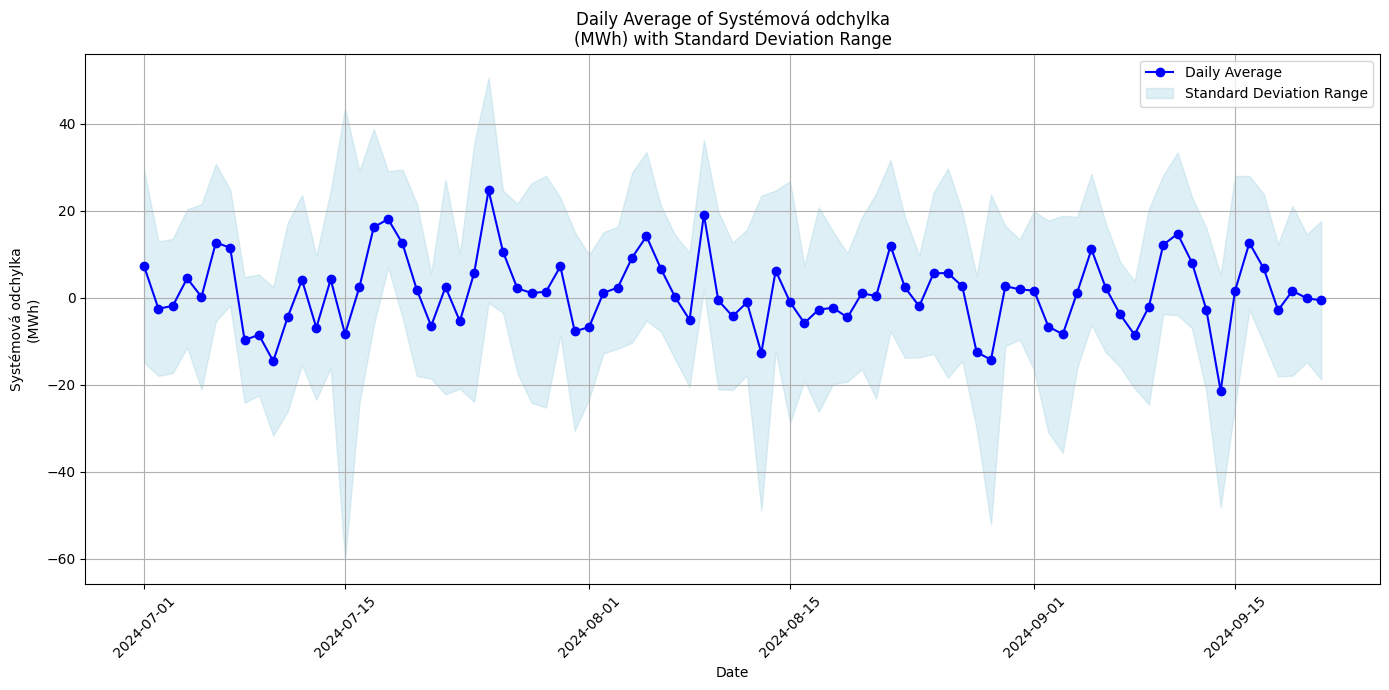

         Den      Perioda  Systémová odchylka\n(MWh)  Index  RollingMean  \
0 2024-07-01  00:00-00:15                      7.846      1          NaN   
1 2024-07-01  00:15-00:30                      9.942      2          NaN   
2 2024-07-01  00:30-00:45                     -3.628      3          NaN   
3 2024-07-01  00:45-01:00                    -17.932      4          NaN   
4 2024-07-01  01:00-01:15                    -23.344      5          NaN   

   RollingStd  
0         NaN  
1         NaN  
2         NaN  
3         NaN  
4         NaN  
Index(['Den', 'Perioda', 'Systémová odchylka\n(MWh)', 'Index', 'RollingMean',
       'RollingStd'],
      dtype='str')


In [ ]:
# Group by the date ('Den') and calculate the average and standard deviation for 'Systémová odchylka\n(MWh)' for each day
daily_avg = train_data.groupby('Den')['Systémová odchylka\n(MWh)'].mean()
daily_std = train_data.groupby('Den')['Systémová odchylka\n(MWh)'].std()

# Calculate the upper and lower bounds for the standard deviation range
upper_bound = daily_avg + daily_std
lower_bound = daily_avg - daily_std

# Plotting the daily average and standard deviation range
plt.figure(figsize=(14, 7))

# Plot the daily average values
plt.plot(daily_avg.index, daily_avg.values, marker='o', color='blue', label='Daily Average')

# Plot the standard deviation range
plt.fill_between(daily_avg.index, lower_bound, upper_bound, color='lightblue', alpha=0.4, label='Standard Deviation Range')

# Customizing plot labels and title
plt.title('Daily Average of Systémová odchylka\n(MWh) with Standard Deviation Range')
plt.xlabel('Date')
plt.ylabel('Systémová odchylka\n(MWh)')
plt.legend()

# Display the plot
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Output to confirm train_data is unchanged
print(train_data.head())
print(train_data.columns)

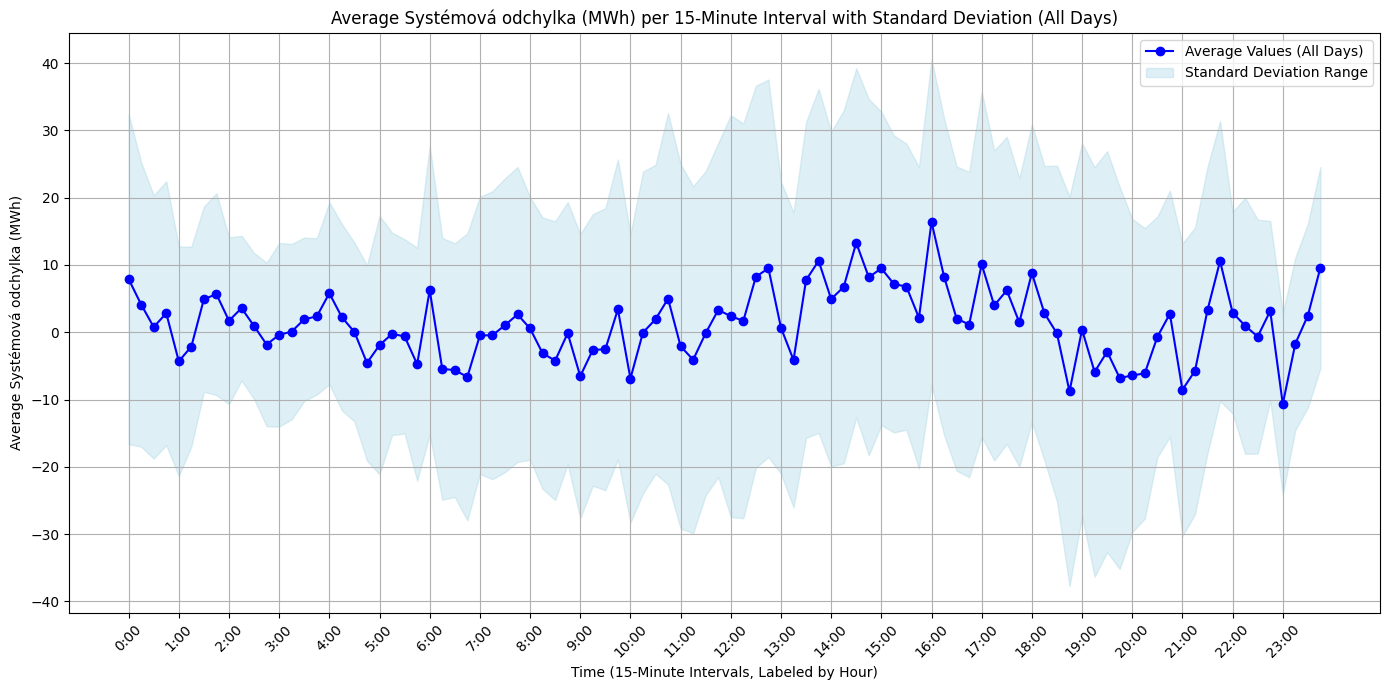

         Den      Perioda  Systémová odchylka\n(MWh)  Index  RollingMean  \
0 2024-07-01  00:00-00:15                      7.846      1          NaN   
1 2024-07-01  00:15-00:30                      9.942      2          NaN   
2 2024-07-01  00:30-00:45                     -3.628      3          NaN   
3 2024-07-01  00:45-01:00                    -17.932      4          NaN   
4 2024-07-01  01:00-01:15                    -23.344      5          NaN   

   RollingStd  
0         NaN  
1         NaN  
2         NaN  
3         NaN  
4         NaN  
Index(['Den', 'Perioda', 'Systémová odchylka\n(MWh)', 'Index', 'RollingMean',
       'RollingStd'],
      dtype='str')


In [ ]:
# Create new variables for average and standard deviation calculations across all days
average_day_new = train_data.groupby('Perioda')['Systémová odchylka\n(MWh)'].mean()
std_dev_day_new = train_data.groupby('Perioda')['Systémová odchylka\n(MWh)'].std()

# Plotting the average values for each 15-minute interval
plt.figure(figsize=(14, 7))
plt.plot(average_day_new.index, average_day_new.values, color='blue', marker='o', label="Average Values (All Days)")

# Plotting the standard deviation band
plt.fill_between(
    average_day_new.index,
    average_day_new - std_dev_day_new,  # Lower bound (mean - std deviation)
    average_day_new + std_dev_day_new,  # Upper bound (mean + std deviation)
    color='lightblue',
    alpha=0.4,
    label="Standard Deviation Range"
)

# Customizing plot labels and title
plt.title('Average Systémová odchylka (MWh) per 15-Minute Interval with Standard Deviation (All Days)')
plt.xlabel('Time (15-Minute Intervals, Labeled by Hour)')
plt.ylabel('Average Systémová odchylka (MWh)')
plt.xticks(ticks=range(0, len(average_day_new.index), 4), labels=[f"{i}:00" for i in range(24)], rotation=45)

# Add grid, legend, and layout adjustments
plt.grid(True)
plt.tight_layout()
plt.legend()
plt.show()

# Output to confirm train_data is unchanged
print(train_data.head())
print(train_data.columns)

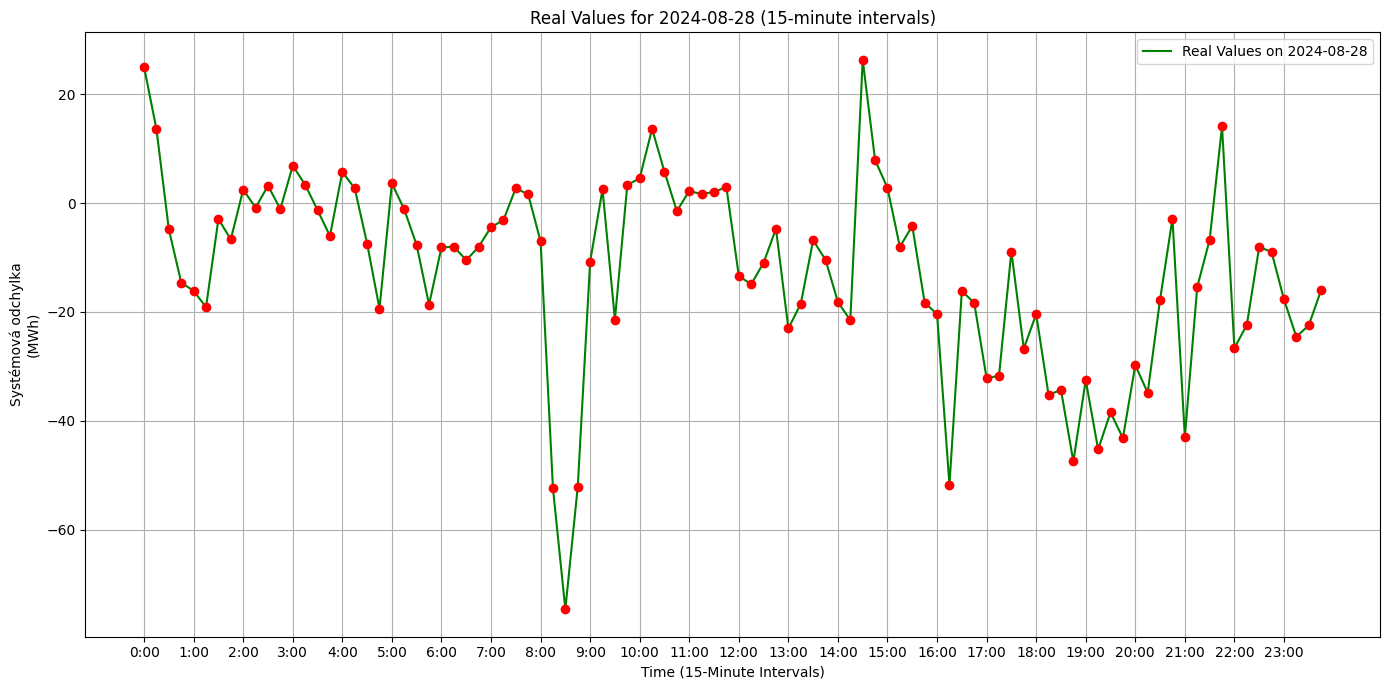

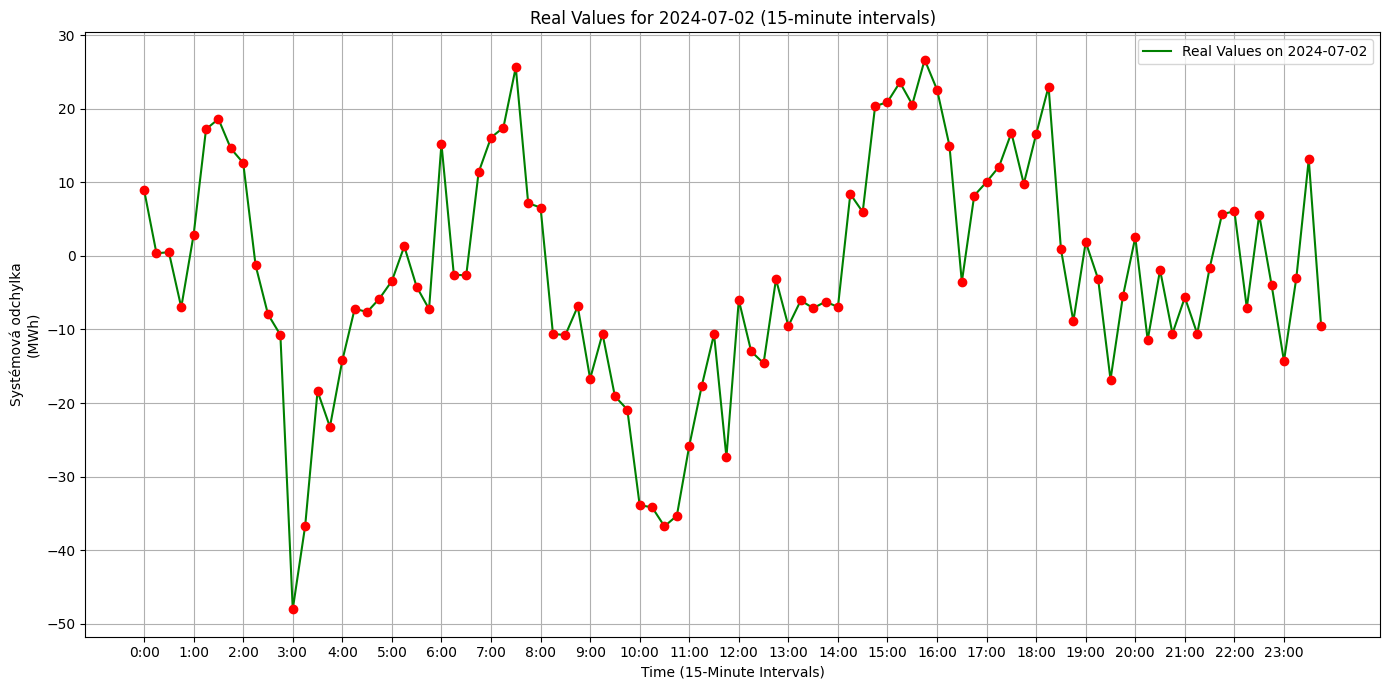

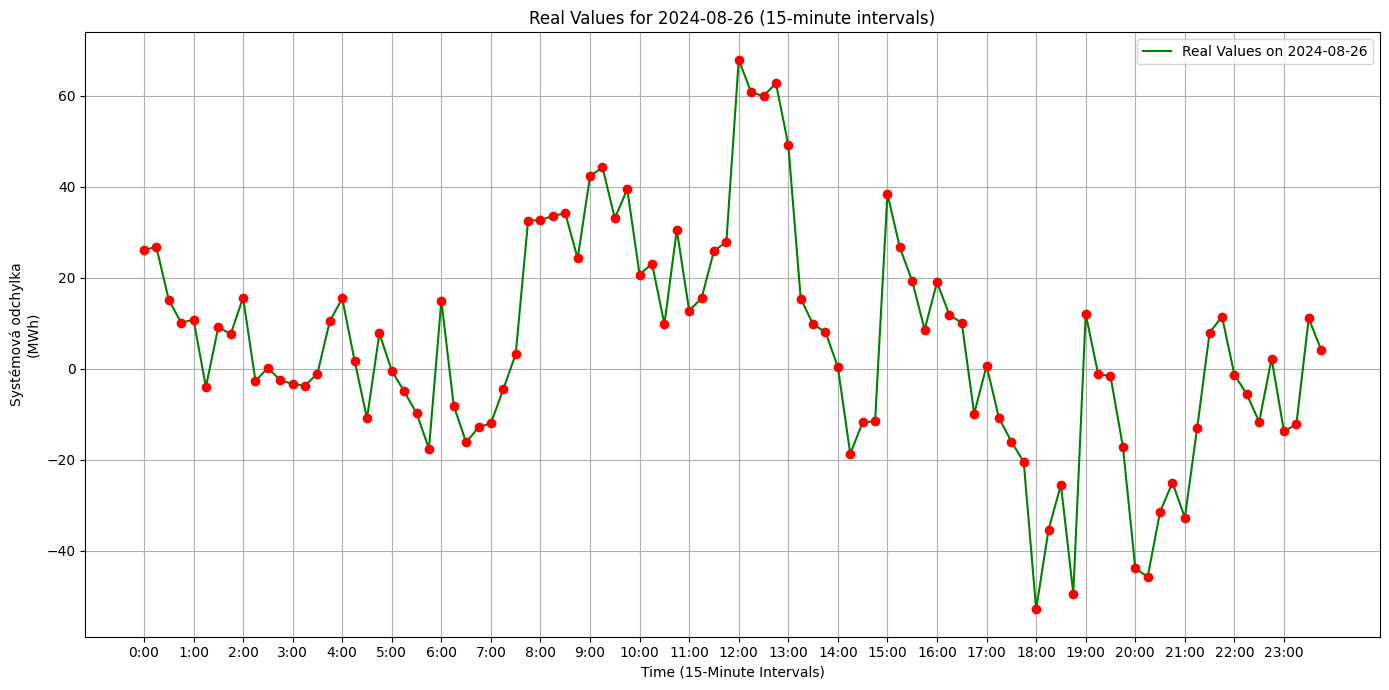

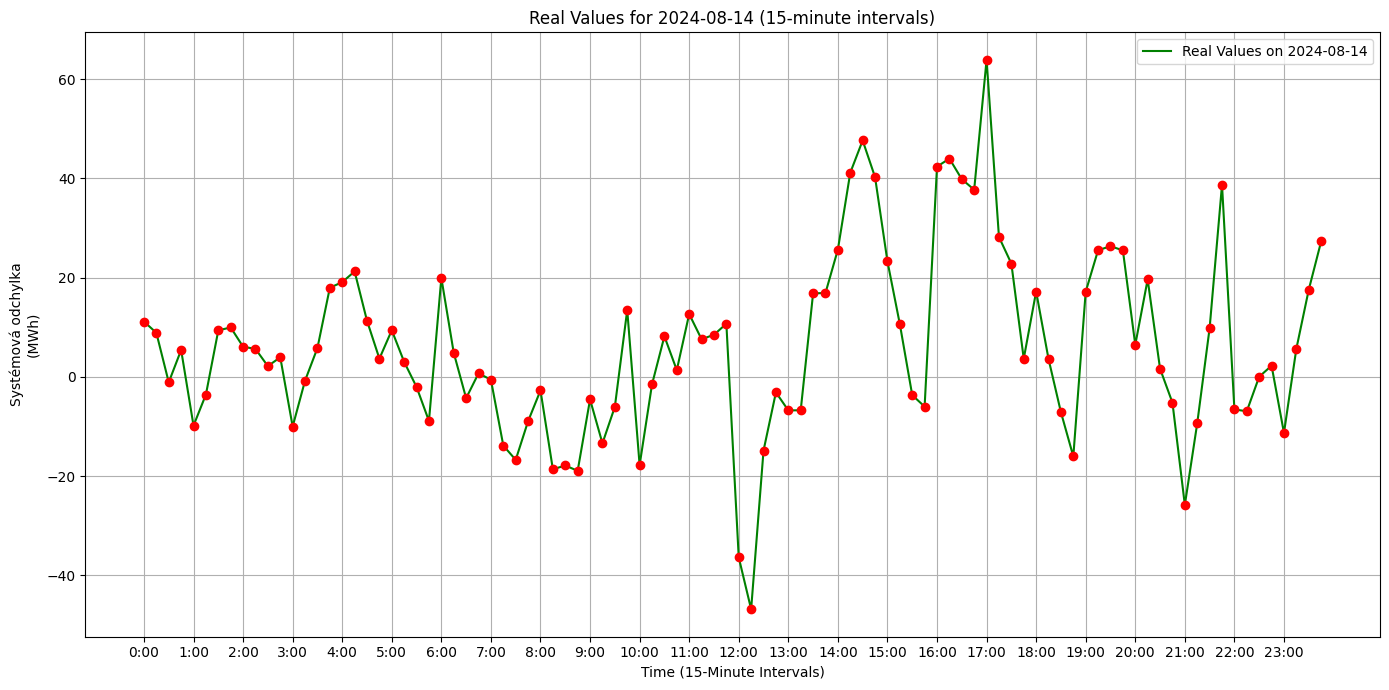

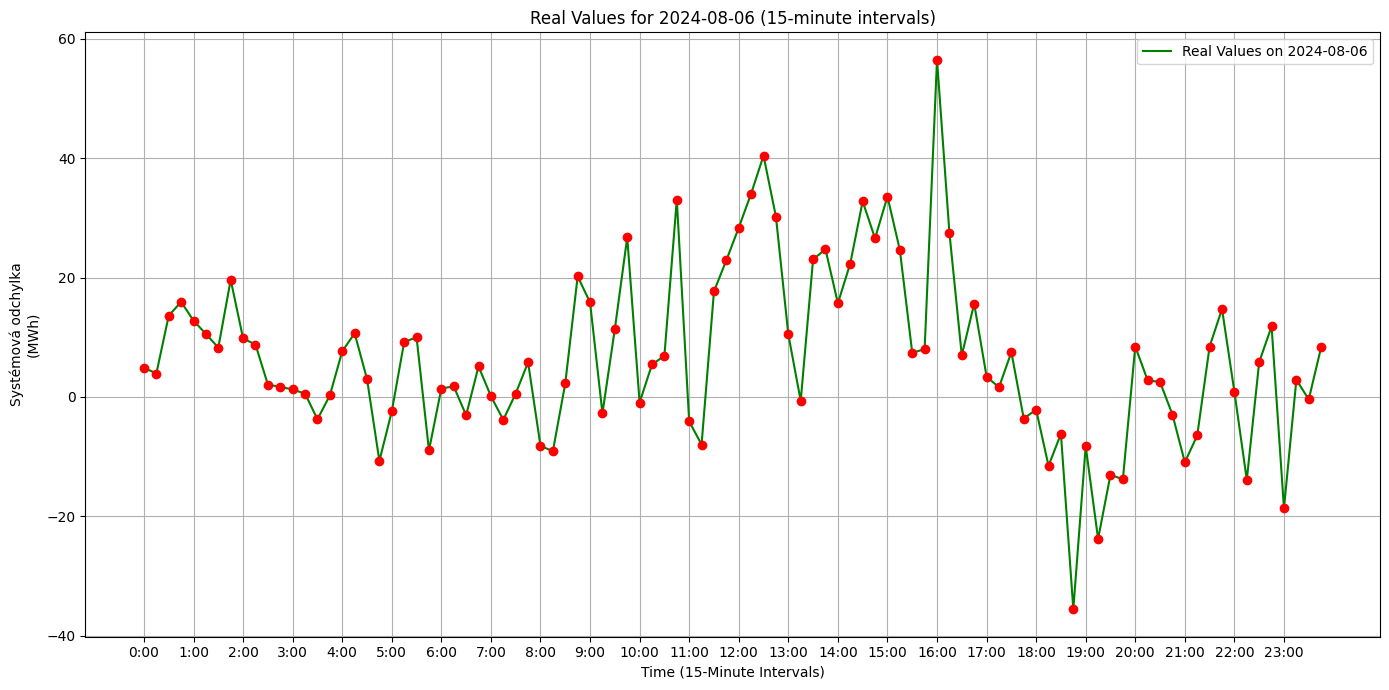

Randomly selected days: [datetime.date(2024, 8, 28) datetime.date(2024, 7, 2)
 datetime.date(2024, 8, 26) datetime.date(2024, 8, 14)
 datetime.date(2024, 8, 6)]
         Den      Perioda  Systémová odchylka\n(MWh)  Index  RollingMean  \
0 2024-07-01  00:00-00:15                      7.846      1          NaN   
1 2024-07-01  00:15-00:30                      9.942      2          NaN   
2 2024-07-01  00:30-00:45                     -3.628      3          NaN   
3 2024-07-01  00:45-01:00                    -17.932      4          NaN   
4 2024-07-01  01:00-01:15                    -23.344      5          NaN   

   RollingStd  
0         NaN  
1         NaN  
2         NaN  
3         NaN  
4         NaN  
Index(['Den', 'Perioda', 'Systémová odchylka\n(MWh)', 'Index', 'RollingMean',
       'RollingStd'],
      dtype='str')


In [ ]:
# Get a list of unique days from the 'Den' column
unique_days = train_data['Den'].dt.date.unique()

# Randomly select 5 unique days from the dataset
random_days = np.random.default_rng(seed=40).choice(unique_days, size=5, replace=False)

# Plot the data for each randomly selected day in separate figures
for specific_day in random_days:
    # Filter the data for the current day
    train_data_day = train_data[train_data['Den'].dt.date == specific_day]

    # Create a new figure for each day
    plt.figure(figsize=(14, 7))

    # Plotting the real values for that one day
    plt.plot(train_data_day['Perioda'], train_data_day['Systémová odchylka\n(MWh)'], color='green', label=f"Real Values on {specific_day}")

    # Highlight the exact data points with scatter (balls)
    plt.scatter(train_data_day['Perioda'], train_data_day['Systémová odchylka\n(MWh)'], color='red', zorder=5)  # Red balls for data points

    # Adding title, labels, and formatting
    plt.title(f'Real Values for {specific_day} (15-minute intervals)')
    plt.xlabel('Time (15-Minute Intervals)')
    plt.ylabel('Systémová odchylka\n(MWh)')

    # Adjust x-axis ticks to label in hours (without changing the data)
    plt.xticks(ticks=range(0, len(train_data_day), 4), labels=[f"{i}:00" for i in range(0, 24)])

    # Adding grid, layout, and legend
    plt.grid(True)
    plt.tight_layout()
    plt.legend()

    # Show the plot
    plt.show()

# Print the selected random days
print("Randomly selected days:", random_days)

print(train_data.head())
print(train_data.columns)

MODEL BUILDING AND EVALUATING:

ARMA:

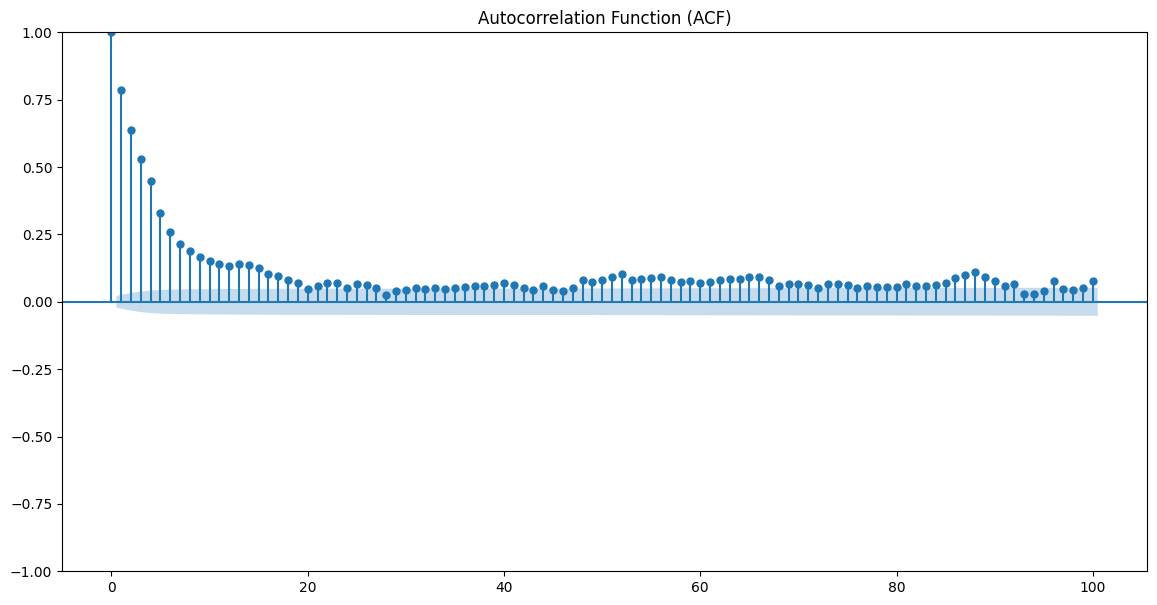

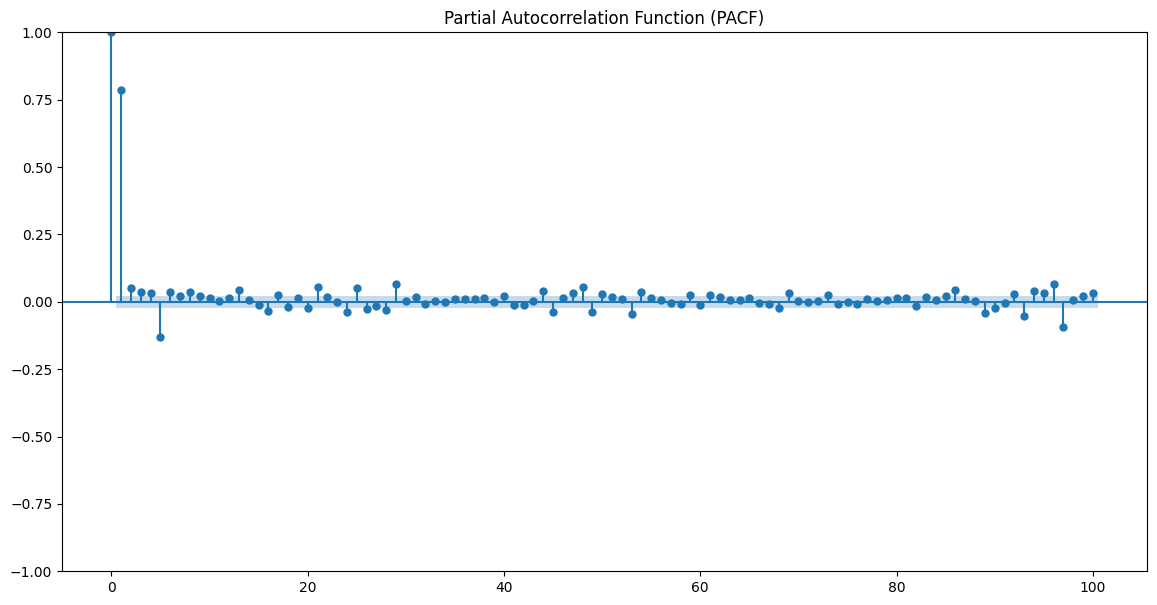

In [ ]:
# EXPLORE CORRELATION STRUCTURE

# Set 'Index' as the index of the DataFrame (just for the ARMA model, not changing your original time-based index)
train_data_arma = train_data.set_index('Index')

# Plotting the Autocorrelation Function (ACF)
plt.figure(figsize=(14, 7))
plot_acf(train_data_arma['Systémová odchylka\n(MWh)'], lags=100, ax=plt.gca())  # You can change 'lags' to control how many lags you want to display
plt.title('Autocorrelation Function (ACF)')
plt.show()


# Plotting the Partial Autocorrelation Function (PACF)
plt.figure(figsize=(14, 7))
plot_pacf(train_data_arma['Systémová odchylka\n(MWh)'], lags=100, ax=plt.gca())  # You can change 'lags' here as well
plt.title('Partial Autocorrelation Function (PACF)')
plt.show()


                                  SARIMAX Results                                   
Dep. Variable:     Systémová odchylka
(MWh)   No. Observations:                 7949
Model:                       ARIMA(1, 0, 1)   Log Likelihood              -31930.765
Date:                      Wed, 14 Oct 2026   AIC                          63869.530
Time:                              16:17:54   BIC                          63897.453
Sample:                                   0   HQIC                         63879.090
                                     - 7949                                         
Covariance Type:                        opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.3072      0.755      1.732      0.083      -0.172       2.786
ar.L1          0.8126      0.006    126.750      0.000       0.800       0.825
ma.L

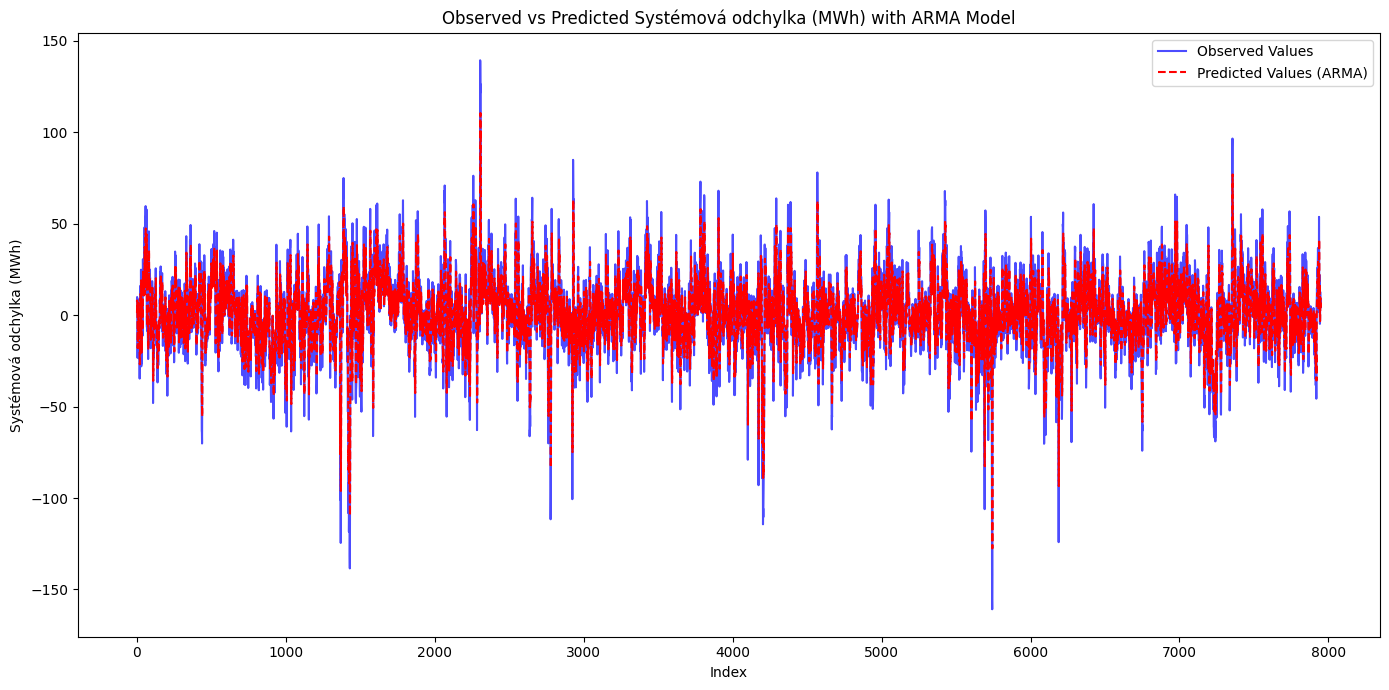

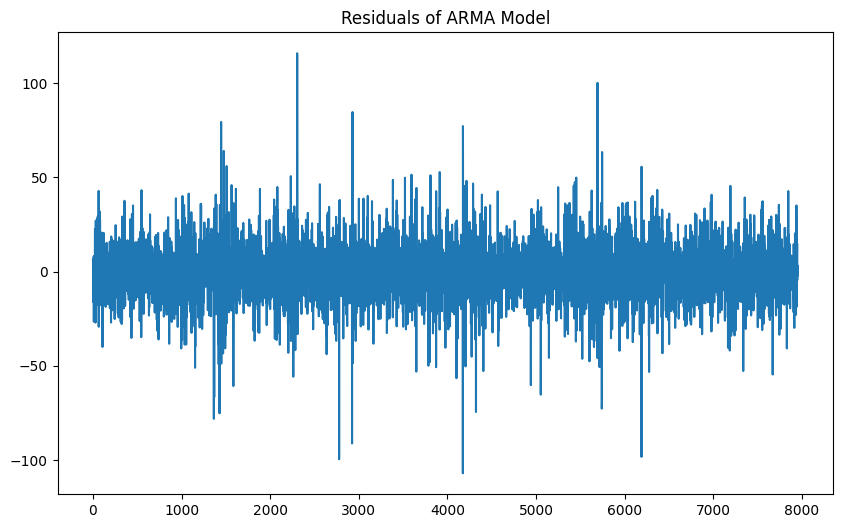

         Den      Perioda  Systémová odchylka\n(MWh)  Index  RollingMean  \
0 2024-07-01  00:00-00:15                      7.846      1          NaN   
1 2024-07-01  00:15-00:30                      9.942      2          NaN   
2 2024-07-01  00:30-00:45                     -3.628      3          NaN   
3 2024-07-01  00:45-01:00                    -17.932      4          NaN   
4 2024-07-01  01:00-01:15                    -23.344      5          NaN   

   RollingStd  
0         NaN  
1         NaN  
2         NaN  
3         NaN  
4         NaN  
Index(['Den', 'Perioda', 'Systémová odchylka\n(MWh)', 'Index', 'RollingMean',
       'RollingStd'],
      dtype='str')


In [14]:
# FIT AND INSPECT SIMPLE ARMA MODEL

# Define the ARMA model (p, q) parameters. Here, we're using ARMA(1, 1) as an example.
# You can tune these parameters based on your needs or use methods like AIC/BIC for selection.
arma_model = ARIMA(train_data_arma['Systémová odchylka\n(MWh)'], order=(1, 0, 1))

# Fit the model
arma_results = arma_model.fit()

# Print the summary of the ARMA model
print(arma_results.summary())

# Optional: Plot the residuals
# Get the predicted values from the ARMA model
arma_pred = arma_results.fittedvalues

# Plot the observed values and the predicted values
plt.figure(figsize=(14, 7))
plt.plot(train_data_arma.index, train_data_arma['Systémová odchylka\n(MWh)'], label='Observed Values', color='blue', alpha=0.7)
plt.plot(train_data_arma.index, arma_pred, label='Predicted Values (ARMA)', color='red', linestyle='--')

# Customize plot labels and title
plt.title('Observed vs Predicted Systémová odchylka (MWh) with ARMA Model')
plt.xlabel('Index')
plt.ylabel('Systémová odchylka (MWh)')
plt.legend()

# Show the plot
plt.tight_layout()
plt.show()


# Plotting residuals to check for randomness
arma_residuals = arma_results.resid
plt.figure(figsize=(10, 6))
plt.plot(arma_residuals)
plt.title('Residuals of ARMA Model')
plt.show()

print(train_data.head())
print(train_data.columns)

In [15]:
# BUILD MUTIPLE ARMA MODELS AND PICK THE BEST 

# Define range of parameters
p = range(0,3)
q = range(0, 19)  # Adjust p and q as needed
d = range(0, 1)      # Adjust d as needed
results_list = []     # List to store the results

# Perform grid search - (2,0,16) is best
for param in [(x, y, z) for x in p for y in d for z in q]:
    try:
        model = sm.tsa.ARIMA(train_data['Systémová odchylka\n(MWh)'], order=param)
        model_fit = model.fit()
        aic = model_fit.aic
        results_list.append((param[0], param[1], param[2], aic))  # Store (p, d, q, AIC)
    except Exception as e:
        continue  # Skip models that fail

# Convert results to a pandas DataFrame
results_df = pd.DataFrame(results_list, columns=['p', 'd', 'q', 'AIC'])

# Display the DataFrame
print(results_df)

# Optionally, sort the DataFrame by AIC
sorted_results_df = results_df.sort_values(by='AIC').reset_index(drop=True)
print("Sorted results by AIC:")
print(sorted_results_df)#

c:\Users\Radovan\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Radovan\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Radovan\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Radovan\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Radov

    p  d   q           AIC
0   0  0   0  71498.439952
1   0  0   1  67133.272233
2   0  0   2  65235.926787
3   0  0   3  64917.496482
4   0  0   4  64215.841285
5   0  0   5  63943.969925
6   0  0   6  63828.890479
7   0  0   7  63807.950297
8   0  0   8  63763.506838
9   0  0   9  63748.290804
10  0  0  10  63728.320413
11  0  0  11  63723.032990
12  0  0  12  63724.577331
13  0  0  13  63726.018912
14  0  0  14  63724.304405
15  0  0  15  63707.071767
16  0  0  16  63709.007269
17  0  0  17  63699.134372
18  0  0  18  63697.696321
19  1  0   0  63891.107837
20  1  0   1  63869.529785
21  1  0   2  63863.482142
22  1  0   3  63864.441014
23  1  0   4  63723.845448
24  1  0   5  63715.212805
25  1  0   6  63708.586435
26  1  0   7  63698.315287
27  1  0   8  63699.935030
28  1  0   9  63695.378316
29  1  0  10  63695.265949
30  1  0  11  63687.789000
31  1  0  12  63687.918527
32  1  0  13  63689.659112
33  1  0  14  63689.512989
34  1  0  15  63690.150624
35  1  0  16  63680.249916
3

In [16]:
# FINAL MODEL

# Fit ARMA(2,16) model
model = sm.tsa.ARIMA(train_data['Systémová odchylka\n(MWh)'], order=(2, 0, 16))  # ARMA(p, d, q), here d=0 as no differencing is applied
model_fit = model.fit()

# Print model summary
print(model_fit.summary())

                                  SARIMAX Results                                   
Dep. Variable:     Systémová odchylka
(MWh)   No. Observations:                 7949
Model:                      ARIMA(2, 0, 16)   Log Likelihood              -31809.761
Date:                      Wed, 14 Oct 2026   AIC                          63659.522
Time:                              16:26:28   BIC                          63799.138
Sample:                                   0   HQIC                         63707.326
                                     - 7949                                         
Covariance Type:                        opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.3094      1.205      1.087      0.277      -1.052       3.671
ar.L1          0.0957      0.037      2.552      0.011       0.022       0.169
ar.L

Mean Squared Error: 168.6434619157393
Sign Accuracy: 75.65%


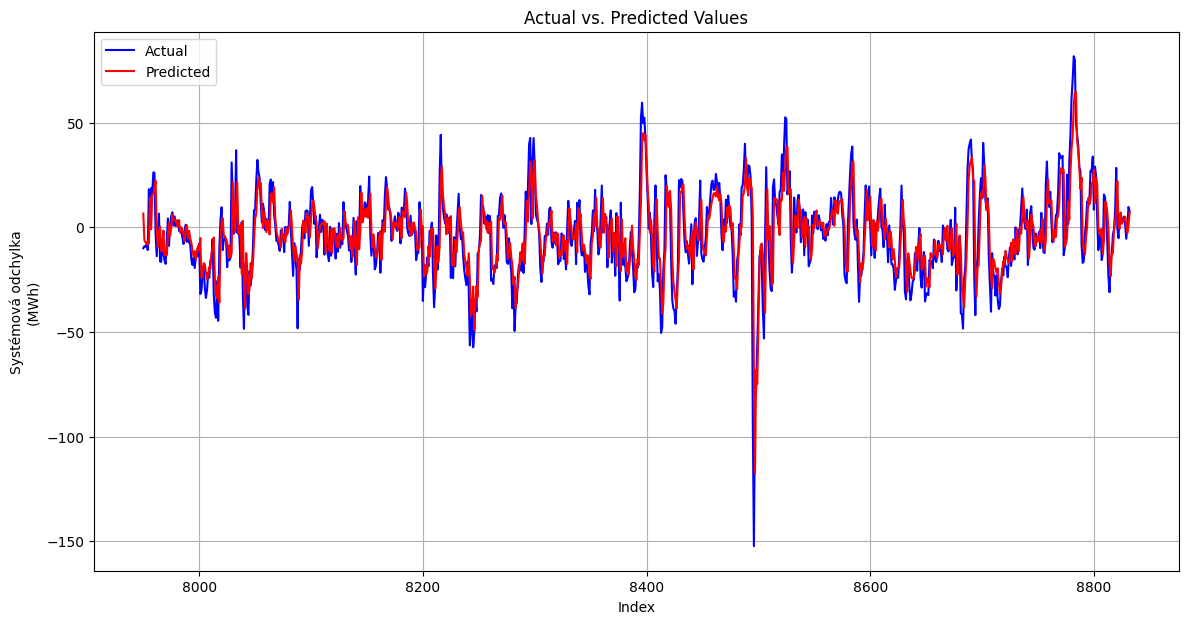

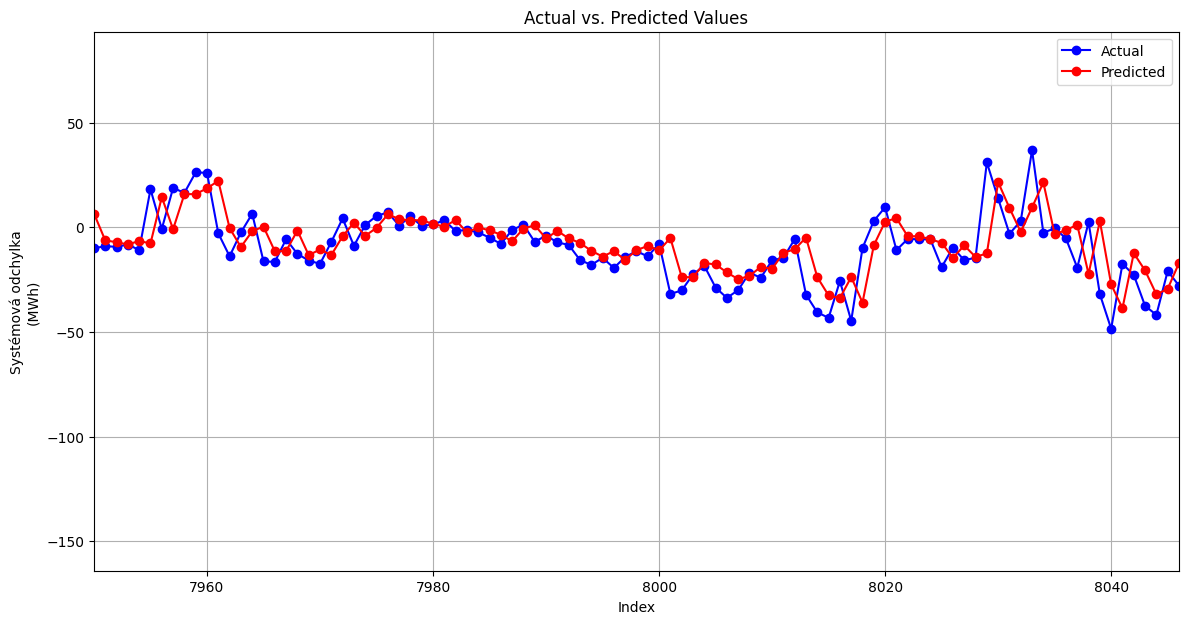

Mean Squared Error: 182.40124338780535
Sign Accuracy: 74.18%


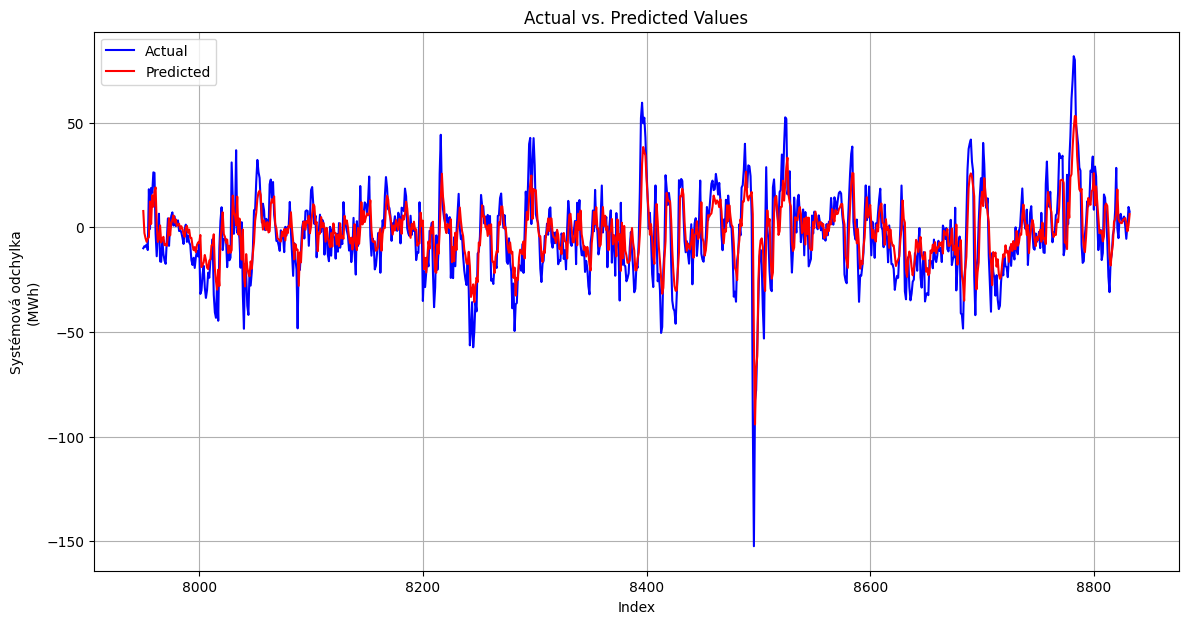

In [17]:
# EVALUATE PREDICTION PERFORMANCE

# Initialize an empty list to store predictions
rolling_predictions = []

# Loop through the dataset from the specified start index
start_idx = 7949

# Iterate over each point in the dataset, using the real observed values to make predictions
for i in range(start_idx, len(df)):
    # Forecast the next value based on the current model state
    pred = model_fit.get_forecast(steps=1).predicted_mean.iloc[0]
    
    # Append the forecast to the rolling predictions
    rolling_predictions.append(pred)
    
    # Update the model's internal state by appending the observed next actual value
    model_fit = model_fit.append([df['Systémová odchylka\n(MWh)'].iloc[i]])

# Convert the rolling predictions into a Series for easier plotting
rolling_predictions_series = pd.Series(rolling_predictions, index=df['Index'][start_idx:])
# 1. Calculate MSE (Mean Squared Error)
# Real values (from validation data, starting at index 7949)
real_values = df['Systémová odchylka\n(MWh)'].iloc[7949:7949+len(rolling_predictions)]

# MSE calculation
mse = mean_squared_error(real_values, rolling_predictions)
print(f"Mean Squared Error: {mse}")

# 2. Calculate the Sign Test (percentage of correct sign predictions)
# Get the sign of real values and predicted values (positive = 1, negative = -1, zero = 0)
real_signs = np.sign(real_values)
predicted_signs = np.sign(rolling_predictions)

# Compare signs (correct if they match)
correct_signs = np.sum(real_signs == predicted_signs)
total_signs = len(real_signs)

sign_accuracy = correct_signs / total_signs * 100
print(f"Sign Accuracy: {sign_accuracy:.2f}%")
# Plot the real values and the rolling predictions
plt.figure(figsize=(14, 7))
plt.plot(df['Index'][start_idx:], df['Systémová odchylka\n(MWh)'][start_idx:], label="Actual", color="blue")
plt.plot(rolling_predictions_series.index, rolling_predictions_series.values, label="Predicted", color="red")
plt.title("Actual vs. Predicted Values")
plt.xlabel("Index")
plt.ylabel("Systémová odchylka\n(MWh)")
plt.legend()
plt.grid(True)
plt.show()
x = 7950

# Plot the real values and the rolling predictions with x-axis limit
plt.figure(figsize=(14, 7))

# Plot actual values with markers
plt.plot(df['Index'][start_idx:], df['Systémová odchylka\n(MWh)'][start_idx:], label="Actual", color="blue", marker='o', markersize=6)

# Plot predicted values with markers
plt.plot(rolling_predictions_series.index, rolling_predictions_series.values, label="Predicted", color="red", marker='o', markersize=6)

plt.title("Actual vs. Predicted Values")
plt.xlabel("Index")
plt.ylabel("Systémová odchylka\n(MWh)")
plt.legend()
plt.grid(True)

# Set the x-axis limit between x and x+96
plt.xlim(x, x + 96)

plt.show()
# Initialize an empty list to store predictions
rolling_predictions2 = []

# Loop through the dataset from the specified start index
start_idx = 7949

# Iterate over each point in the dataset, using the real observed values to make predictions
for i in range(start_idx, len(df)):
    # Forecast the next value based on the current model state
    pred = model_fit.get_forecast(steps=2).predicted_mean.iloc[1]
    # Append the forecast to the rolling predictions
    rolling_predictions2.append(pred)
    
    # Update the model's internal state by appending the observed next actual value
    model_fit = model_fit.append([df['Systémová odchylka\n(MWh)'].iloc[i]])

# Convert the rolling predictions into a Series for easier plotting
rolling_predictions2_series = pd.Series(rolling_predictions2, index=df['Index'][start_idx:])
# 1. Calculate MSE (Mean Squared Error)
# Real values (from validation data, starting at index 7949)
real_values = df['Systémová odchylka\n(MWh)'].iloc[7949:7949+len(rolling_predictions2)]

# MSE calculation
mse = mean_squared_error(real_values, rolling_predictions2)
print(f"Mean Squared Error: {mse}")

# 2. Calculate the Sign Test (percentage of correct sign predictions)
# Get the sign of real values and predicted values (positive = 1, negative = -1, zero = 0)
real_signs = np.sign(real_values)
predicted_signs = np.sign(rolling_predictions2)

# Compare signs (correct if they match)
correct_signs = np.sum(real_signs == predicted_signs)
total_signs = len(real_signs)

sign_accuracy = correct_signs / total_signs * 100
print(f"Sign Accuracy: {sign_accuracy:.2f}%")
# Plot the real values and the rolling predictions
plt.figure(figsize=(14, 7))
plt.plot(df['Index'][start_idx:], df['Systémová odchylka\n(MWh)'][start_idx:], label="Actual", color="blue")
plt.plot(rolling_predictions2_series.index, rolling_predictions2_series.values, label="Predicted", color="red")
plt.title("Actual vs. Predicted Values")
plt.xlabel("Index")
plt.ylabel("Systémová odchylka\n(MWh)")
plt.legend()
plt.grid(True)
plt.show()